# LEAR vs DNN — model comparison

Full validation forecasts of every model from `01_LEAR.ipynb` and `02_DNN.ipynb`, evaluated side by side:

- one table with metrics for all models,
- Diebold-Mariano (DM) and Giacomini-White (GW) tests for all model pairs.

Forecasts are read from `results/<family>/val/full/<model>.csv`.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent.parent))

import pandas as pd
from epftoolbox.evaluation import plot_multivariate_DM_test, plot_multivariate_GW_test

from src.utils.epf import forecast_path
from src.utils.evaluation import as_daily_inputs, compare_models, load_forecasts
from src.utils.file_io import load_final_dataset

/opt/homebrew/Caskroom/miniforge/base/envs/epf-lear-dnn/lib/python3.10/site-packages/hyperopt/atpe.py:19: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
dataset_train = load_final_dataset("epf", "pl", "train")
dataset_val = load_final_dataset("epf", "pl", "val")
dataset_full = pd.concat([dataset_train, dataset_val])
prices = dataset_full["PL_price"]

models = [
    {"model": "LEAR_364", "family": "lear"},
    {"model": "LEAR_728", "family": "lear"},
    {"model": "LEAR_1092", "family": "lear"},
    {"model": "DNN_1", "family": "dnn"},
    {"model": "DNN_2", "family": "dnn"},
    {"model": "DNN_3", "family": "dnn"},
]

## 1. Metrics

All models are scored on the same 126 validation days. MAE and RMSE are in EUR/MWh. rMAE is scaled by the weekly naive forecast (the same hour one week earlier), so a value below 1 beats it. Lower is better for all three.

In [3]:
forecasts = load_forecasts(
    [
        forecast_path(m["model"], split="val", run="full", family=m["family"])
        for m in models
    ]
)

compare_models(forecasts, prices, metrics=["rMAE", "MAE", "RMSE"])

,rMAE,MAE,RMSE
model,,,
LEAR_364,0.684534,18.531291,29.753640
LEAR_728,0.671208,18.170537,28.764687
LEAR_1092,0.672119,18.195204,28.902790
DNN_1,0.698246,18.902479,30.957843
DNN_2,0.686614,18.587599,29.724201
DNN_3,0.685365,18.553771,30.829777


## 2. DM and GW tests

Both tests compare two forecasts on their daily absolute errors, with all 24 hours of a day tested jointly. DM tests whether one model is more accurate than the other on average. GW is its conditional version, which also takes the previous day's loss difference into account.

Each cell of the heat map is the p-value of the one-sided test that the model on the x-axis is more accurate than the model on the y-axis. Green and yellow (p < 0.05) mean a significant difference, red (0.05–0.10) is borderline, and black (p > 0.10) means the two models cannot be told apart.

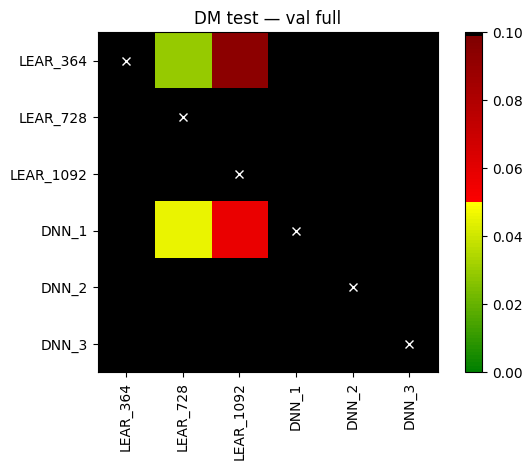

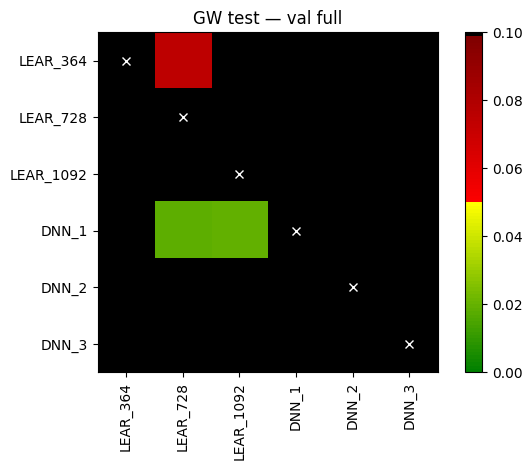

In [9]:
p_real, preds = as_daily_inputs(prices, forecasts)
plot_multivariate_DM_test(p_real, preds, norm=1, title="DM test — val full")
plot_multivariate_GW_test(p_real, preds, norm=1, title="GW test — val full")

## 3. Conclusions

`LEAR_728` is the best model on all three metrics (rMAE 0.671, MAE 18.2, RMSE 28.8), followed by `LEAR_1092`. On rMAE and MAE every LEAR window is ahead of every DNN, while on RMSE `DNN_2` (29.7) is level with `LEAR_364`.

The tests show few significant differences. Among the DNNs only `DNN_1` is significantly worse than the best LEAR models (DM against `LEAR_728`, GW against `LEAR_728` and `LEAR_1092`), and `LEAR_728` also beats `LEAR_364` in DM. `DNN_2` and `DNN_3` cannot be told apart from any LEAR model or from each other. The validation set has only 126 days, so the tests have little power and the small gaps in the table should not be over-read.